In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv("books_data.csv")

print("Dataset loaded successfully!")

display(df.head())

Dataset loaded successfully!


,Book Name,Price,Rating,Availability
0,A Light in the Attic,Â£51.77,Three,In stock
1,Tipping the Velvet,Â£53.74,One,In stock
2,Soumission,Â£50.10,One,In stock
3,Sharp Objects,Â£47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock


In [ ]:
print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

Dataset Shape:
(20, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Book Name     20 non-null     object
 1   Price         20 non-null     object
 2   Rating        20 non-null     object
 3   Availability  20 non-null     object
dtypes: object(4)
memory usage: 772.0+ bytes


In [ ]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Book Name       0
Price           0
Rating          0
Availability    0
dtype: int64


In [ ]:
print("Dataset Shape:", df.shape)

Dataset Shape: (20, 4)


In [ ]:
print("Column Names:")
print(df.columns)

Column Names:
Index(['Book Name', 'Price', 'Rating', 'Availability'], dtype='object')


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Book Name     20 non-null     object
 1   Price         20 non-null     object
 2   Rating        20 non-null     object
 3   Availability  20 non-null     object
dtypes: object(4)
memory usage: 772.0+ bytes


In [ ]:
df.describe(include="all")

,Book Name,Price,Rating,Availability
count,20,20,20,20
unique,20,20,5,1
top,A Light in the Attic,Â£51.77,One,In stock
freq,1,1,6,20


In [ ]:
print(df.isnull().sum())

Book Name       0
Price           0
Rating          0
Availability    0
dtype: int64


In [ ]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [13]:
df["Price"] = df["Price"].str.replace("Â£", "", regex=False).astype(float)

print("Price converted successfully!")

display(df.head())

Price converted successfully!


,Book Name,Price,Rating,Availability
0,A Light in the Attic,51.77,Three,In stock
1,Tipping the Velvet,53.74,One,In stock
2,Soumission,50.10,One,In stock
3,Sharp Objects,47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,54.23,Five,In stock


In [14]:
print(df.dtypes)

Book Name        object
Price           float64
Rating           object
Availability     object
dtype: object


In [15]:
print("Average Price:", df["Price"].mean())

print("Maximum Price:", df["Price"].max())

print("Minimum Price:", df["Price"].min())

print("Total Price:", df["Price"].sum())

Average Price: 38.048500000000004
Maximum Price: 57.25
Minimum Price: 13.99
Total Price: 760.97


In [16]:
print(df["Rating"].value_counts())

Rating
One      6
Five     4
Four     4
Three    3
Two      3
Name: count, dtype: int64


In [17]:
print(df["Availability"].value_counts())

Availability
In stock    20
Name: count, dtype: int64


/tmp/ipykernel_6994/1230235620.py:10: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


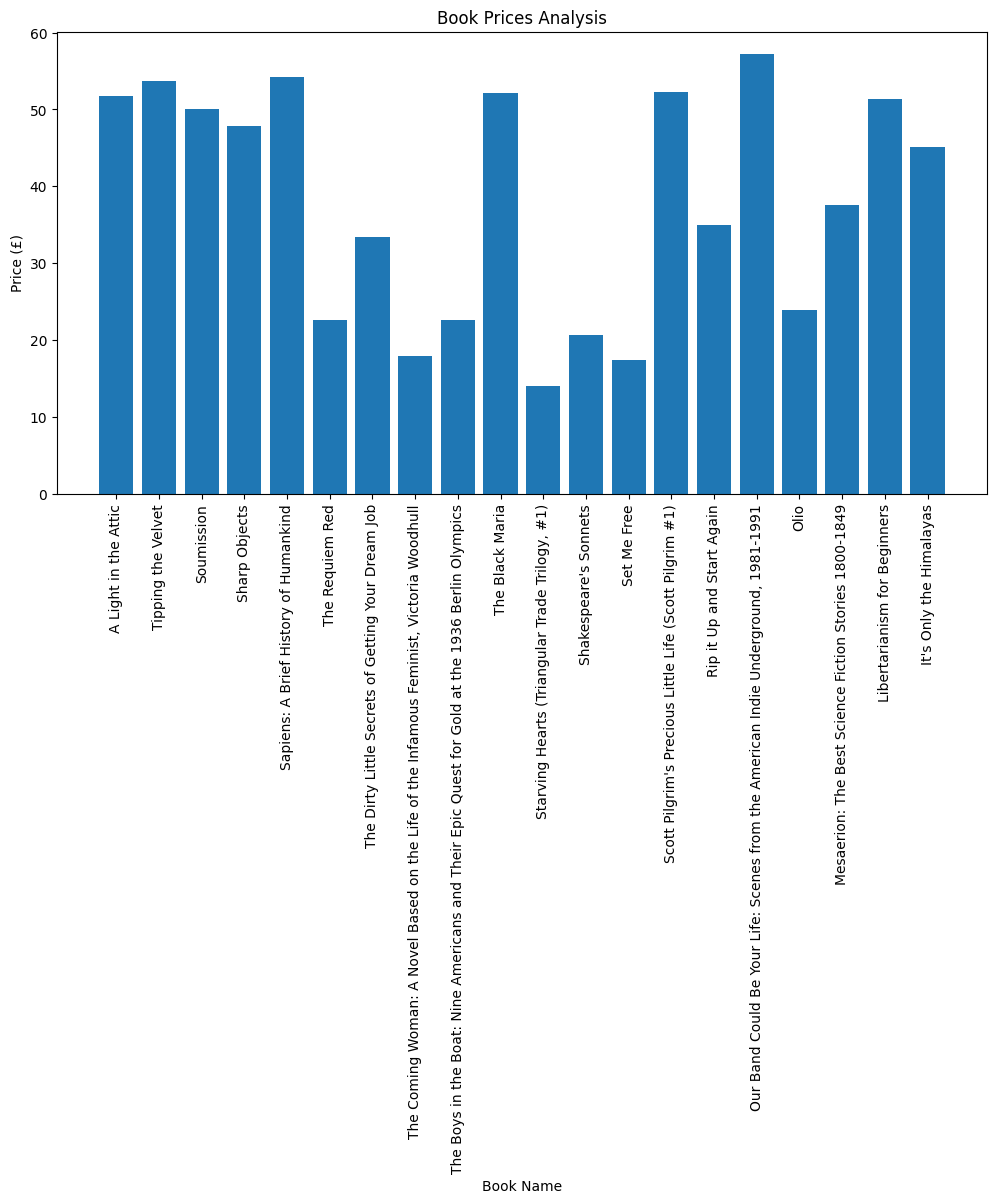

In [18]:
plt.figure(figsize=(12, 6))

plt.bar(df["Book Name"], df["Price"])

plt.title("Book Prices Analysis")
plt.xlabel("Book Name")
plt.ylabel("Price (£)")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

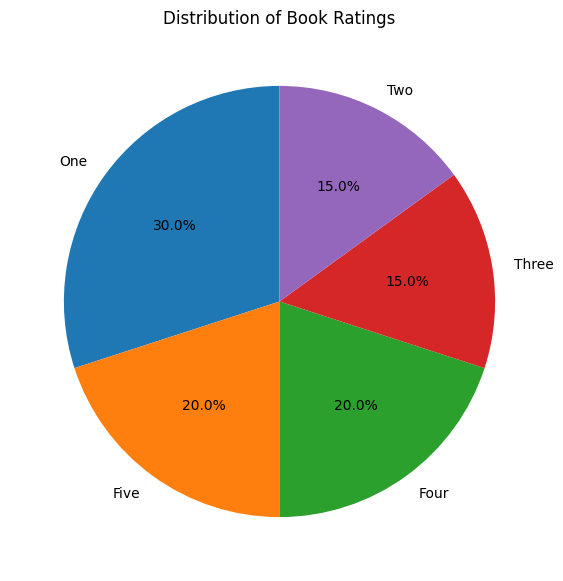

In [19]:
rating_counts = df["Rating"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(rating_counts, labels=rating_counts.index,
        autopct="%1.1f%%", startangle=90)

plt.title("Distribution of Book Ratings")
plt.show()

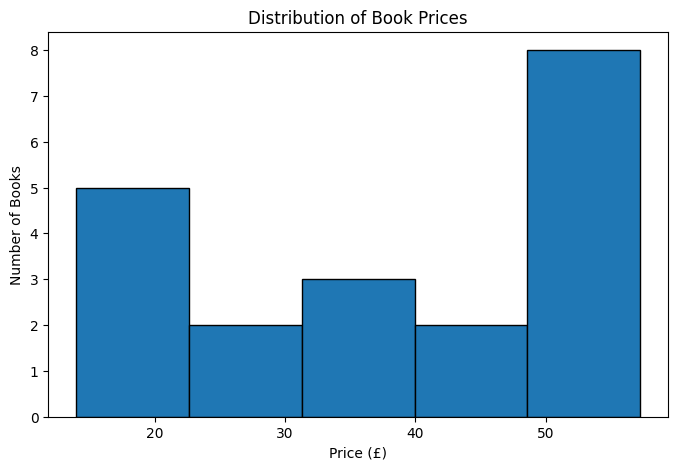

In [20]:
plt.figure(figsize=(8, 5))

plt.hist(df["Price"], bins=5, edgecolor="black")

plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")

plt.show()

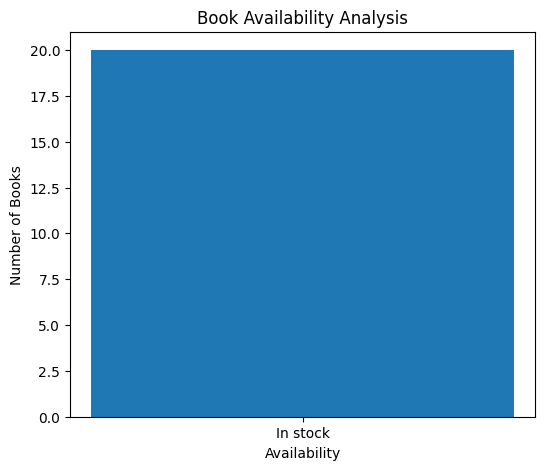

In [21]:
availability_counts = df["Availability"].value_counts()

plt.figure(figsize=(6, 5))

plt.bar(availability_counts.index, availability_counts.values)

plt.title("Book Availability Analysis")
plt.xlabel("Availability")
plt.ylabel("Number of Books")

plt.show()

In [22]:
print("1. Most Expensive Book:")
print(df.loc[df["Price"].idxmax(), "Book Name"])

print("\n2. Cheapest Book:")
print(df.loc[df["Price"].idxmin(), "Book Name"])

print("\n3. Average Book Price:")
print(df["Price"].mean())

print("\n4. Most Common Rating:")
print(df["Rating"].mode()[0])

print("\n5. Available Books:")
print((df["Availability"] == "In stock").sum())

1. Most Expensive Book:
Our Band Could Be Your Life: Scenes from the American Indie Underground, 1981-1991

2. Cheapest Book:
Starving Hearts (Triangular Trade Trilogy, #1)

3. Average Book Price:
38.048500000000004

4. Most Common Rating:
One

5. Available Books:
20


In [23]:
print("Price Analysis:")

print("Mean:", df["Price"].mean())
print("Median:", df["Price"].median())
print("Standard Deviation:", df["Price"].std())

Price Analysis:
Mean: 38.048500000000004
Median: 41.38
Standard Deviation: 15.135230520039556


In [24]:
rating_order = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

df["Rating_Number"] = df["Rating"].map(rating_order)

correlation = df["Price"].corr(df["Rating_Number"])

print("Price and Rating Correlation:", correlation)

Price and Rating Correlation: -0.07585689715186737


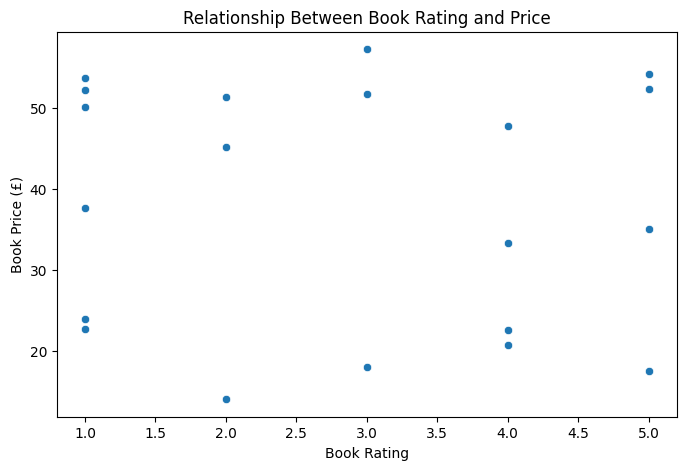

In [25]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="Rating_Number", y="Price")

plt.title("Relationship Between Book Rating and Price")
plt.xlabel("Book Rating")
plt.ylabel("Book Price (£)")

plt.show()

In [26]:
print("Rating-wise Average Book Price:")
print(df.groupby("Rating")["Price"].mean().sort_values(ascending=False))

print("\nPrice Distribution:")
print(df["Price"].describe())

print("\nBooks with unusually high prices:")
Q1 = df["Price"].quantile(0.25)
Q3 = df["Price"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[(df["Price"] < lower_limit) | (df["Price"] > upper_limit)]
print(outliers[["Book Name", "Price"]])

Rating-wise Average Book Price:
Rating
Three    42.316667
One      40.018333
Five     39.750000
Two      36.830000
Four     31.105000
Name: Price, dtype: float64

Price Distribution:
count    20.000000
mean     38.048500
std      15.135231
min      13.990000
25%      22.637500
50%      41.380000
75%      51.865000
max      57.250000
Name: Price, dtype: float64

Books with unusually high prices:
Empty DataFrame
Columns: [Book Name, Price]
Index: []


In [27]:
from scipy.stats import pearsonr

correlation, p_value = pearsonr(
    df["Price"],
    df["Rating_Number"]
)

print("Correlation:", correlation)
print("P-value:", p_value)

if p_value < 0.05:
    print("There is a statistically significant relationship.")
else:
    print("There is no statistically significant relationship.")

Correlation: -0.07585689715186739
P-value: 0.7505934038042006
There is no statistically significant relationship.
